# Standard New Keynesian Model
### Microfoundations → steady state → determinacy → rational-expectations solver → structural IRFs → welfare

Quarterly model. All rates and gaps are **decimal deviations** unless displayed as `100 ×` percentage points. The exercises below are **calibrated simulations, not US empirical estimates**.

** A zero-inflation, efficient steady state with a subsidy eliminating monopoly markup; representative household; linear production; Calvo pricing; Taylor rule; three reduced-form disturbances. The welfare comparisons use a standard second-order approximation around the efficient steady state; the cost-push wedge is added to the linear NKPC for policy experiments. A full microfounded stochastic markup welfare expansion and consumption-equivalent variation are beyond this notebook.

** household and firm FOCs, exact steady state, log-linear equations, Blanchard–Kahn, matrix residual, three IRFs, and commitment/discretion/Taylor welfare rankings.

In [ ]:
# 무균실 속의 표준 시계...

## 1. Household / 대표가계

Maximize
$$\mathbb E_0\sum_{t=0}^\infty \beta^t\left[\frac{C_t^{1-\sigma}-1}{1-\sigma}-\frac{N_t^{1+\varphi}}{1+\varphi}\right]$$
subject to $P_t C_t+B_t=W_tN_t+(1+i_{t-1})B_{t-1}+\Pi_t+T_t$ and a no-Ponzi condition. For $\sigma=1$, use $\log C_t$.

FOCs:
$$U_C=C_t^{-\sigma},\qquad \frac{W_t}{P_t}=C_t^\sigma N_t^\varphi,$$
$$1=\beta(1+i_t)\,\mathbb E_t\left[\left(\frac{C_{t+1}}{C_t}\right)^{-\sigma}\frac1{\Pi_{t+1}}\right].$$
Log-linear Euler equation (rate deviations from steady state):
$$c_t=\mathbb E_t c_{t+1}-\sigma^{-1}(i_t-\mathbb E_t\pi_{t+1}-\bar r).$$
In gap form (after subtracting natural allocation):
$$\boxed{x_t=\mathbb E_t x_{t+1}-\sigma^{-1}(i_t-\mathbb E_t\pi_{t+1}-r_t^n).}$$
$ r_t^n $ here is the deviation in the natural real rate (not its gross steady-state level).

## 2. Firms / Calvo pricing

Final-good aggregator and demand:
$$Y_t=\left(\int_0^1 Y_t(j)^{(\epsilon-1)/\epsilon}dj\right)^{\epsilon/(\epsilon-1)},\qquad Y_t(j)=\left(P_t(j)/P_t\right)^{-\epsilon}Y_t.$$
Intermediate production: $Y_t(j)=A_tN_t(j)$; flexible-price desired markup $\mu=\epsilon/(\epsilon-1)$.

Calvo probability of *not* resetting is $\theta$:
$$P_t^{1-\epsilon}=\theta P_{t-1}^{1-\epsilon}+(1-\theta)(P_t^*)^{1-\epsilon}.$$
An optimizing resetter sets its price to the discounted expected marginal-cost markup:
$$P_t^*=\mu\frac{\mathbb E_t\sum_{k\geq0}(\beta\theta)^k C_{t+k}^{-\sigma}Y_{t+k|t} P_{t+k} MC_{t+k}^{net}}{\mathbb E_t\sum_{k\geq0}(\beta\theta)^k C_{t+k}^{-\sigma}Y_{t+k|t}},$$
where $MC^{net}$ denotes real marginal cost *net of the constant subsidy*; consequently the numerator has nominal cost $P\,MC^{net}$. 

With $\bar\pi=0$ and a subsidy offsetting the steady-state markup, marginal cost in deviations satisfies $\widehat{mc}_t=(\sigma+\varphi)x_t$. Then:
$$\boxed{\pi_t=\beta\mathbb E_t\pi_{t+1}+\kappa x_t+u_t,\quad\kappa=\frac{(1-\theta)(1-\beta\theta)}{\theta}(\sigma+\varphi).}$$
The wedge $u_t$ is an added time-varying cost-push/markup disturbance. The efficient flexible-price natural output with linear production is $y_t^n=\frac{1+\varphi}{\sigma+\varphi}a_t$ when other primitives are held constant.

## 3. Steady state and linearized equilibrium

At $\bar A=1$, zero net inflation $\bar\Pi=1$, and efficiency-restoring subsidy: $\bar C=\bar Y=\bar N=1$, $\bar R=1/\beta$, $\bar i=\beta^{-1}-1$ (quarterly net nominal interest rate). The subsidy implied by producer markup is chosen so after-subsidy pricing delivers the efficient allocation.

**Three-equation system:**
$$\begin{aligned}x_t&=\mathbb E_t x_{t+1}-\frac1\sigma(i_t-\mathbb E_t\pi_{t+1}-r_t^n),\\\pi_t&=\beta\mathbb E_t\pi_{t+1}+\kappa x_t+u_t,\\i_t&=\phi_\pi\pi_t+\phi_x x_t+\nu_t.\end{aligned}$$
Exogenous states $s_t=(r_t^n,u_t,\nu_t)'=R s_{t-1}+\varepsilon_t$ where $R=\mathrm{diag}(\rho_r,\rho_u,\rho_m)$.

## 4. Determinacy theorem
Write $Az_t=B\mathbb E_t z_{t+1}+Ds_t$, $z_t=(x_t,\pi_t)'$:
$$A=\begin{pmatrix}\sigma+\phi_x&\phi_\pi\\-\kappa&1\end{pmatrix},\quad B=\begin{pmatrix}\sigma&1\\0&\beta\end{pmatrix},\quad D=\begin{pmatrix}1&0&-1\\0&1&0\end{pmatrix}.$$
The characteristic polynomial $\det(A-zB)$ equals
$$p(z)=\sigma\beta z^2-[\sigma(1+\beta)+\beta\phi_x+\kappa]z+\sigma+\phi_x+\kappa\phi_\pi.$$
Two forward-looking variables require **two generalized eigenvalues outside the unit circle**. Apply the second-order Jury conditions to reciprocal roots $w=1/z$. Under $\sigma,\kappa>0$, $0<\beta<1$ and nonnegative rule coefficients, the binding condition is
$$\boxed{\kappa(\phi_\pi-1)+(1-\beta)\phi_x>0.}$$
At equality a unit root arises. The solution below is only certified for determinate parameterizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.linalg import eigvals
np.set_printoptions(precision=8, suppress=True)
@dataclass(frozen=True)
class Params:
    beta:float=.99
    sigma:float=1.
    varphi:float=1.
    epsilon:float=6.
    theta:float=.75
    phi_pi:float=1.5
    phi_x:float=.125
    rho_r:float=.8
    rho_u:float=.5
    rho_m:float=.5
    std_r:float=.01
    std_u:float=.005
    std_m:float=.01
    @property
    def lam_p(self):return (1-self.theta)*(1-self.beta*self.theta)/self.theta
    @property
    def kappa(self):return self.lam_p*(self.sigma+self.varphi)
    @property
    def lam_x(self):return self.kappa/self.epsilon
p=Params()
print('Steady state:',{'C':1.,'Y':1.,'N':1.,'gross_pi':1.,'net_quarterly_rate':1/p.beta-1})
print('lambda_p, kappa, lambda_x:',p.lam_p,p.kappa,p.lam_x)

Steady state: {'C': 1.0, 'Y': 1.0, 'N': 1.0, 'gross_pi': 1.0, 'net_quarterly_rate': 0.010101010101010166}
lambda_p, kappa, lambda_x: 0.08583333333333336 0.17166666666666672 0.02861111111111112


In [2]:
def matrices(p):
    A=np.array([[p.sigma+p.phi_x,p.phi_pi],[-p.kappa,1.]])
    B=np.array([[p.sigma,1.],[0.,p.beta]])
    D=np.array([[1.,0.,-1.],[0.,1.,0.]])
    R=np.diag([p.rho_r,p.rho_u,p.rho_m])
    return A,B,D,R

def solve_re(p):
    A,B,D,R=matrices(p)
    roots=eigvals(A,B)
    if not np.all(np.abs(roots)>1+1e-9):
        raise ValueError('Blanchard-Kahn determinacy failed: '+str(roots))
    K=np.kron(np.eye(3),A)-np.kron(R.T,B)
    F=np.linalg.solve(K,D.reshape(-1,order='F')).reshape((2,3),order='F')
    resid=A@F-B@F@R-D
    assert np.max(abs(resid.ravel()))<1e-10
    rate=p.phi_x*F[0,:]+p.phi_pi*F[1,:]+np.array([0.,0.,1.])
    T=np.vstack([F,rate])
    return roots,F,T,np.max(abs(resid.ravel()))
roots,F,T,resid=solve_re(p)
print('Generalized eigenvalues:',roots)
print('Moduli:',np.abs(roots))
print('Taylor principle test:',p.kappa*(p.phi_pi-1)+(1-p.beta)*p.phi_x)
print('Policy matrix F [gap, inflation] x [natural rate, cost-push, MP]:\n',F)
print('Max equilibrium equation residual:',resid)
assert (np.abs(roots)>1).sum()==2

Generalized eigenvalues: [1.15425084+0.25331727j 1.15425084-0.25331727j]
Moduli: [1.18172105 1.18172105]
Taylor principle test: 0.08708333333333336
Policy matrix F [gap, inflation] x [natural rate, cost-push, MP]:
 [[ 1.10775786 -2.05215904 -1.03634032]
 [ 0.91425528  1.2825994  -0.3522873 ]]
Max equilibrium equation residual: 2.220446049250313e-16


## 5. Three structural IRFs / 구조충격별 반응

For a unit innovation to state $j$ of magnitude $\sigma_j$ at date 0, $z_h=FR^h e_j\sigma_j$, and $i_h=\phi_xx_h+\phi_\pi\pi_h+\nu_h$. A `+1pp` shock means `0.01` in the rate *deviation*; cost-push innovation is `0.005`. Graphs plot $100\times$ each deviation (percentage points).

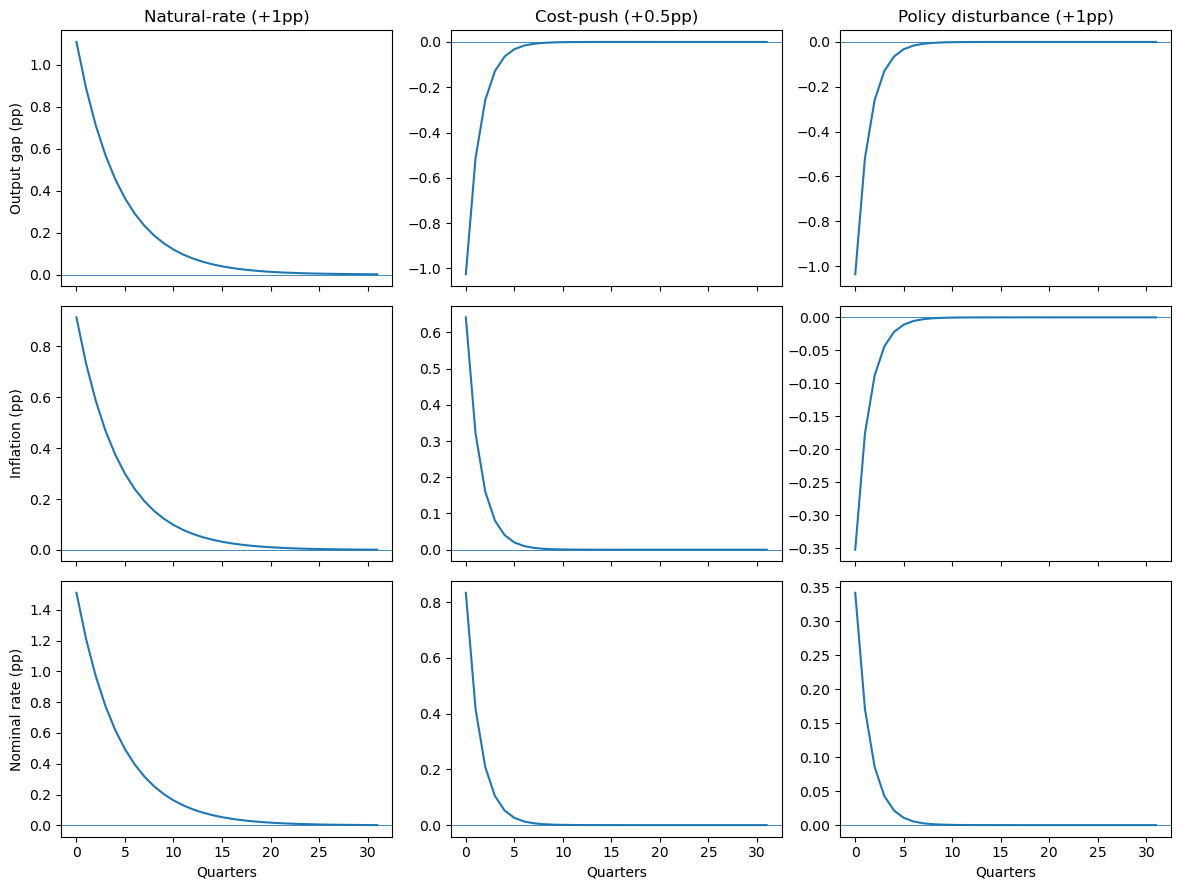

Impact responses, percentage points:


,x,inflation,nominal i
Natural-rate (+1pp),1.1078,0.9143,1.5099
Cost-push (+0.5pp),-1.0261,0.6413,0.8337
Policy disturbance (+1pp),-1.0363,-0.3523,0.3420


In [3]:
def compute_irfs(p,H=32):
    roots,F,T,_=solve_re(p)
    _,_,_,R=matrices(p)
    sizes=np.array([p.std_r,p.std_u,p.std_m])
    response=np.zeros((3,H,3))
    for j in range(3):
        state=np.eye(3)[:,j]*sizes[j]
        for h in range(H):
            response[j,h,:]=T@state
            state=R@state
    return response
RIRF=compute_irfs(p)
labels=['Natural-rate (+1pp)','Cost-push (+0.5pp)','Policy disturbance (+1pp)']
fig,axs=plt.subplots(3,3,figsize=(12,9),sharex=True)
for shock in range(3):
    for var in range(3):
        axs[var,shock].plot(np.arange(RIRF.shape[1]),100*RIRF[shock,:,var])
        axs[var,shock].axhline(0,lw=.6)
        if var==0: axs[var,shock].set_title(labels[shock])
        if shock==0:axs[var,shock].set_ylabel(['Output gap (pp)','Inflation (pp)','Nominal rate (pp)'][var])
        if var==2: axs[var,shock].set_xlabel('Quarters')
plt.tight_layout()
plt.show()
print('Impact responses, percentage points:')
display(pd.DataFrame(100*RIRF[:,0,:],index=labels,columns=['x','inflation','nominal i']).round(4))

## 6. Welfare and monetary-policy design

With an efficient steady state, the conventional second-order representative-household welfare approximation is proportional to
$$\frac12\mathbb E_0\sum_{t\geq0}\beta^t\left[\pi_t^2+\lambda_x x_t^2\right],\qquad \lambda_x=\kappa/\epsilon.$$
**Conditional loss**, for a one-time *positive* cost-push shock $u_t=\rho_u^t u_0$. Values depend on the normalization and are *not* consumption-equivalent welfare. The simple loss and NKPC are treated as policy design primitives for this exercise.

**Discretion (Markov perfect in the cost-push state):** optimize current $\pi,x$ taking next-period private expectations as given. FOC $\kappa\pi_t+\lambda_xx_t=0$; thus $\pi_t^{D}=u_t/(1-\beta\rho_u+\kappa^2/\lambda_x)$ and $x_t^{D}=-\kappa\pi_t^D/\lambda_x$.

**Ramsey commitment from date 0:** FOCs imply $\pi_t+(\lambda_x/\kappa)(x_t-x_{t-1})=0$ for $t\ge1$ and $\pi_0+(\lambda_x/\kappa)x_0=0$ (initial multiplier zero). Solve jointly with the NKPC, truncating at sufficiently large $H$ and setting terminal $\pi_H=0$.

**Taylor:** use the determinate RE equilibrium with cost-push innovation only. Same shock in all cases. The interest rate that implements discretion or Ramsey can be recovered from the IS equation given the natural-rate shock (here zero); no constraint is imposed on it.

,discounted loss,impact inflation (pp),impact x (pp),loss vs Taylor (%)
Policy,,,,
Commitment,0.000010,0.232469,-1.394813,-67.605589
Discretion,0.000014,0.325733,-1.954397,-51.202389
Taylor,0.000029,0.641300,-1.026080,0.000000


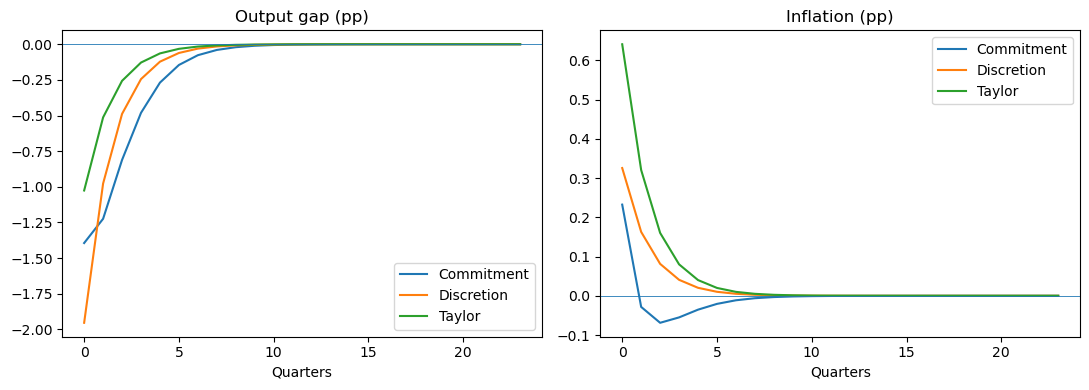

In [4]:
def welfare(x,pi,p):
    return .5*np.sum(p.beta**np.arange(len(x))*(pi**2+p.lam_x*x**2))

def compare_policies(p,H=160):
    u=p.std_u*p.rho_u**np.arange(H)
    mat=np.zeros((2*H,2*H)); b=np.zeros(2*H)
    for t in range(H):
        # NKPC: pi_t - beta E(pi_{t+1}) - kappa x_t = u_t
        mat[t,t]=-p.kappa
        mat[t,H+t]=1.
        if t+1<H: mat[t,H+t+1]=-p.beta
        b[t]=u[t]
        # Commitment targeting, with x_{-1}=0 initial multiplier
        mat[H+t,H+t]=1.
        mat[H+t,t]=p.lam_x/p.kappa
        if t>0:mat[H+t,t-1]=-p.lam_x/p.kappa
    z=np.linalg.solve(mat,b)
    commit=(z[:H],z[H:])
    pi_d=u/(1-p.beta*p.rho_u+p.kappa**2/p.lam_x)
    disc=(-p.kappa/p.lam_x*pi_d,pi_d)
    _,F,_,_=solve_re(p)
    taylor=(F[0,1]*u,F[1,1]*u)
    return {'Commitment':commit,'Discretion':disc,'Taylor':taylor}
results=compare_policies(p)
rows=[]
for name,(x,pi) in results.items():
    rows.append([name,welfare(x,pi,p),100*pi[0],100*x[0]])
policies=pd.DataFrame(rows,columns=['Policy','discounted loss','impact inflation (pp)','impact x (pp)']).set_index('Policy')
policies['loss vs Taylor (%)']=100*(policies['discounted loss']/policies.loc['Taylor','discounted loss']-1)
display(policies)
assert policies.loc['Commitment','discounted loss']<policies.loc['Discretion','discounted loss']<policies.loc['Taylor','discounted loss']
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,(x,pi) in results.items():
    axs[0].plot(np.arange(24),100*x[:24],label=name)
    axs[1].plot(np.arange(24),100*pi[:24],label=name)
for ax,title in zip(axs,['Output gap (pp)','Inflation (pp)']):
    ax.axhline(0,lw=.6);ax.set_title(title);ax.set_xlabel('Quarters');ax.legend()
plt.tight_layout();plt.show()

## 7. Determinacy robustness and checks / 경계조건

A change in $\phi_\pi$ can cross the generalized Taylor-principle threshold. The regime chart computes actual generalized roots (rather than presuming every parameterization admits the same linear solution).

<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:13: SyntaxWarning: invalid escape sequence '\p'
C:\Users\gayeon\AppData\Local\Temp\ipykernel_25340\1213730714.py:13: SyntaxWarning: invalid escape sequence '\p'
  ax.set(xlabel='Taylor inflation response $\phi_\pi$',ylabel='Minimum eigenvalue modulus',title='BK determinacy boundary')


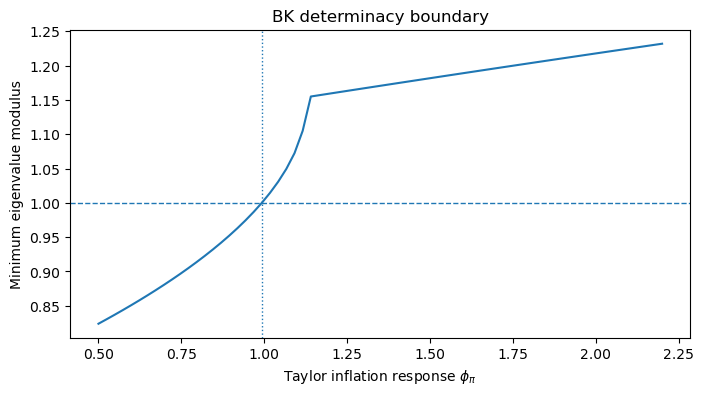

Generalized Taylor principle threshold: 0.9927184466019418


In [5]:
from dataclasses import replace
phi_grid=np.linspace(.5,2.2,70)
minimum_modulus=[]
for ph in phi_grid:
    pp=replace(p,phi_pi=float(ph))
    A,B,_,_=matrices(pp)
    minimum_modulus.append(np.min(np.abs(eigvals(A,B))))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(phi_grid,minimum_modulus)
ax.axhline(1.,ls='--',lw=1)
cutoff=1-(1-p.beta)*p.phi_x/p.kappa
ax.axvline(cutoff,ls=':',lw=1)
ax.set(xlabel='Taylor inflation response $\phi_\pi$',ylabel='Minimum eigenvalue modulus',title='BK determinacy boundary')
plt.show()
print('Generalized Taylor principle threshold:',cutoff)
assert abs(cutoff-(1-.01*.125/p.kappa))<1e-9

## 8. Reproducibility, limitations, next stage

1. The model is a **first-order approximate** equilibrium around a zero-inflation steady state. True nonlinear welfare evaluation requires higher-order approximations, price-dispersion dynamics and explicit stochastic primitives.
2. Under a strict household microfoundation, a markup wedge affects price setting and potentially second-order welfare; here the cost-push experiment is the standard *linear-policy benchmark*. Claims about global Ramsey optimality do not follow.
3. The vectorized $F$ solution is valid for these exogenous AR(1) processes when the BK test succeeds. A general model with endogenous predetermined states requires QZ/gensys (or equivalent).
4. The `+1pp` shocks are **calibration choices**; figures are not empirical estimates. Conditional losses are in normalized units.
5. **Stage 2:** US output/inflation/Fed funds observation equations, measurement error, explicit priors, Kalman log-likelihood, posterior sampling, identification checks, and historical decomposition.

**Research mechanism for Stages 3–5:** quantify whether heterogeneity in belief revision changes equilibrium allocations **holding mean expectations constant**, then solve the welfare-optimal policy under the modified economy.